# 🏋️ 05 · Training a Small Network from Scratch

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 5 of 6
> Course notes: pages 3–5 (sigmoid units, $w_{ji}\leftarrow w_{ji}+\Delta w_{ji}$, backprop for output and hidden layers) · Mitchell Table 4.2 (the BACKPROPAGATION algorithm)

Notebooks 01–04 built all the parts: shapes, forward pass, output-layer and hidden-layer gradients. Now we put them in a **loop** and actually *train* networks – first on XOR (the problem a single neuron can never solve), then on a tangled 3-class spiral.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | The training loop: shuffle → forward → loss → backward → update, repeated over **epochs** |
| 2 | **Mini-batch** stochastic gradient descent and **momentum** |
| 3 | Watching a 2-2-1 sigmoid network learn XOR, exactly as in the notes |
| 4 | Training a 2-64-64-3 network on a spiral and watching its decision regions form |
| 5 | How the learning rate, momentum and batch size change training |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
SPIRAL_CMAP = ListedColormap([C["blue"], C["orange"], C["aqua"]])
REGION3_CMAP = ListedColormap(["#d6e6f8", "#fcdccd", "#cdeee2"])

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax(Z):
    Z = Z - Z.max(axis=0, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=0, keepdims=True)

---
## 1 · The variables

### 📖 Notation for the whole of module 02 (same as the course notes)

| Symbol | Shape | Meaning |
|---|---|---|
| $L$ | number | number of layers with weights (hidden + output). The input is "layer 0". |
| $n_l$ | number | number of neurons in layer $l$ ($n_0$ = number of inputs) |
| $\vec x = o^{[0]}$ | $n_0\times1$ | one input example, a **column** vector |
| $w_{ji}$ | number | weight on the wire **from** neuron $i$ (layer $l-1$) **to** neuron $j$ (layer $l$). First index = destination. |
| $W^{[l]}$ | $n_l\times n_{l-1}$ | all weights of layer $l$; **row $j$** = the incoming weights of neuron $j$ (notes: $W^{h1}_{5\times4}$) |
| $b^{[l]}$ | $n_l\times1$ | biases of layer $l$, one per neuron (the weight of the constant input $x_0=1$) |
| $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | $n_l\times1$ | net inputs of layer $l$; entry $j$ is $net_j=\sum_i w_{ji}\,o_i+b_j$ |
| $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ | outputs (activations) of layer $l$; $g$ = activation function, e.g. sigmoid |
| $x_{ji}$ | number | the input that arrives at neuron $j$ from $i$, i.e. $x_{ji}=o_i$ (Mitchell / notes) |
| $t_k$ | number | target for output neuron $k$ |
| $E$ | number | the error (loss) we minimise |
| $\delta_j=-\dfrac{\partial E}{\partial net_j}$ | number | **error term** of neuron $j$ ("how much the error drops if $net_j$ rises") |
| $\eta$ | number | learning rate |
| $N$ | number | batch size; a batch is $X\in\mathbb R^{n_0\times N}$ with **one example per column** |

The notes also name layers by role: $h1$, $h2$ (hidden) and $o$ (output), e.g. $o^{h1}=\sigma(W^{h1}x+b^{h1})$.
New in this notebook:

| Symbol | Meaning |
|---|---|
| epoch | one full pass over the training set |
| $B$ | **mini-batch size**: number of examples used for one update |
| $\theta$ | "any parameter" (every $W^{[l]}$ and $b^{[l]}$) |
| $g=\partial E/\partial\theta$ | its gradient on the current mini-batch |
| $\mu$ | **momentum** coefficient, e.g. 0.9 |
| $v$ | **velocity**: running memory of past updates (same shape as $\theta$) |

---
## 2 · The training loop 🔄

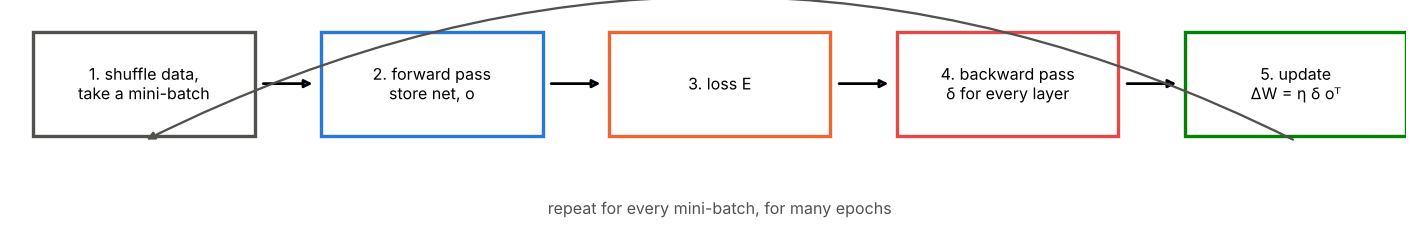

In [2]:
fig, ax = plt.subplots(figsize=(13, 2.4))
steps = [("1. shuffle data,\ntake a mini-batch", C["muted"]), ("2. forward pass\nstore net, o", C["blue"]),
         ("3. loss E", C["orange"]), ("4. backward pass\nδ for every layer", C["red"]),
         ("5. update\nΔW = η δ oᵀ", C["green"])]
for i, (txt, col) in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 2.6, 0), 2.0, 1.0, fc="white", ec=col, lw=2.2))
    ax.text(i * 2.6 + 1.0, 0.5, txt, ha="center", va="center", fontsize=10.5)
    if i < len(steps) - 1:
        ax.annotate("", xy=(i * 2.6 + 2.55, 0.5), xytext=(i * 2.6 + 2.05, 0.5), arrowprops=dict(arrowstyle="-|>", lw=1.8))
ax.annotate("", xy=(1.0, -0.05), xytext=(4 * 2.6 + 1.0, -0.05),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color=C["muted"], connectionstyle="arc3,rad=0.25"))
ax.text(6.2, -0.75, "repeat for every mini-batch, for many epochs", ha="center", color=C["muted"])
ax.set_xlim(-0.2, 12.4); ax.set_ylim(-1.0, 1.2); ax.axis("off")
plt.tight_layout(); plt.show()

### Mini-batch SGD
The notes' $E$ sums over the whole dataset $D$, which gives the exact gradient but only **one** update per epoch (batch GD, module 01). Using a random **mini-batch** of $B$ examples per update gives a noisy but cheap gradient estimate and many updates per epoch. $B=1$ is the notes' *stochastic/incremental* gradient descent.

### Momentum 🎳
Plain SGD: $\theta\leftarrow\theta-\eta\,g$. With momentum we keep a **velocity** $v$:

$$v\leftarrow\mu\,v-\eta\,g,\qquad \theta\leftarrow\theta+v$$

*Intuition:* a ball rolling downhill. Consistent gradients add up and the ball speeds up along the valley; gradients that flip sign (zig-zag across a narrow valley, as in module 01) cancel out. With $\mu=0$ it is plain SGD.

---
## 3 · A compact MLP class 💻

Everything from notebooks 02–04 in one class, in the notes' notation (columns = examples, $W^{[l]}$ is $n_l\times n_{l-1}$, $\delta=-\partial E/\partial net$).

In [3]:
class MLP:
    """Fully-connected network trained with backprop + mini-batch SGD (+ momentum).
    hidden: 'sigmoid' | 'tanh' | 'relu'      output: 'sigmoid_mse' (notes) | 'softmax_ce' (classification)"""

    ACT = {"sigmoid": (sigmoid,                       lambda net, o: o * (1 - o)),
           "tanh":    (np.tanh,                       lambda net, o: 1 - o ** 2),
           "relu":    (lambda z: np.maximum(0, z),    lambda net, o: (net > 0).astype(float))}

    def __init__(self, sizes, hidden="relu", output="softmax_ce", seed=0, init_scale=None):
        r = np.random.default_rng(seed)
        gain = 2.0 if hidden == "relu" else 1.0                      # He for ReLU, Xavier otherwise
        self.W = [r.normal(0, init_scale or np.sqrt(gain / sizes[l - 1]), (sizes[l], sizes[l - 1]))
                  for l in range(1, len(sizes))]                     # W^[l]: (n_l × n_{l-1})
        self.b = [np.zeros((n, 1)) for n in sizes[1:]]               # b^[l]: (n_l × 1)
        self.vW = [np.zeros_like(W) for W in self.W]                 # momentum velocities
        self.vb = [np.zeros_like(b) for b in self.b]
        self.hidden, self.output = hidden, output

    def forward(self, X):
        """X: (n_0 × N). Stores net^[l] and o^[l] for backprop."""
        g = self.ACT[self.hidden][0]
        self.net, self.o = [None], [X]
        L = len(self.W)
        for l in range(L):
            NET = self.W[l] @ self.o[-1] + self.b[l]                 # net = W o_prev + b
            self.net.append(NET)
            if l < L - 1:
                self.o.append(g(NET))
            else:
                self.o.append(sigmoid(NET) if self.output == "sigmoid_mse" else softmax(NET))
        return self.o[-1]

    def loss(self, O, T):
        if self.output == "sigmoid_mse":
            return 0.5 * np.sum((T - O) ** 2) / T.shape[1]           # ½ squared error, averaged per example
        return -np.sum(T * np.log(O + 1e-12)) / T.shape[1]           # mean cross-entropy

    def backward(self, T):
        """Returns gradients ∂E/∂W, ∂E/∂b for the batch (mean over examples)."""
        gprime = self.ACT[self.hidden][1]
        N, L = T.shape[1], len(self.W)
        O = self.o[-1]
        delta = (T - O) * O * (1 - O) / N if self.output == "sigmoid_mse" else (T - O) / N   # δ^[L]
        gW, gb = [None] * L, [None] * L
        for l in reversed(range(L)):
            gW[l] = -delta @ self.o[l].T                             # ∂E/∂W^[l] = -δ o_prevᵀ
            gb[l] = -delta.sum(axis=1, keepdims=True)
            if l > 0:
                delta = gprime(self.net[l], self.o[l]) * (self.W[l].T @ delta)   # δ^[l-1]
        return gW, gb

    def step(self, gW, gb, lr, momentum=0.0):
        for l in range(len(self.W)):
            self.vW[l] = momentum * self.vW[l] - lr * gW[l]          # v ← μ v − η g
            self.vb[l] = momentum * self.vb[l] - lr * gb[l]
            self.W[l] += self.vW[l]                                  # θ ← θ + v
            self.b[l] += self.vb[l]

    def predict(self, X):
        return self.forward(X).argmax(axis=0)

    def fit(self, X, T, X_test=None, T_test=None, epochs=100, batch=32, lr=0.1, momentum=0.0,
            seed=0, snapshot_epochs=(), snapshot_fn=None):
        r = np.random.default_rng(seed)
        N = X.shape[1]
        hist = {k: [] for k in ("loss", "test_loss", "acc", "test_acc")}
        self.snapshots = {}
        for ep in range(1, epochs + 1):
            idx = r.permutation(N)                                   # 1. shuffle every epoch
            for s in range(0, N, batch):
                cols = idx[s:s + batch]                              #    take a mini-batch
                self.forward(X[:, cols])                             # 2. forward
                gW, gb = self.backward(T[:, cols])                   # 3-4. loss gradient by backprop
                self.step(gW, gb, lr, momentum)                      # 5. update
            O = self.forward(X)                                      # bookkeeping on the full sets
            hist["loss"].append(self.loss(O, T))
            hist["acc"].append(np.mean(O.argmax(0) == T.argmax(0)) if T.shape[0] > 1 else np.mean((O > 0.5) == T))
            if X_test is not None:
                Ot = self.forward(X_test)
                hist["test_loss"].append(self.loss(Ot, T_test))
                hist["test_acc"].append(np.mean(Ot.argmax(0) == T_test.argmax(0)))
            if ep in snapshot_epochs and snapshot_fn is not None:
                self.snapshots[ep] = snapshot_fn(self)
        return hist

### 🔍 Walk-through of `fit`
| Line | Step of the loop |
|---|---|
| `idx = r.permutation(N)` | 1. new random order every epoch (so mini-batches differ) |
| `cols = idx[s:s + batch]` | 1. the next $B$ examples (columns) |
| `self.forward(X[:, cols])` | 2. forward pass, storing $net^{[l]},o^{[l]}$ |
| `self.backward(T[:, cols])` | 3–4. $\delta^{[L]}$, then $\delta^{[l]}=g'\odot W^\top\delta^{[l+1]}$, gradients $-\delta\,o^\top$ |
| `self.step(...)` | 5. $v\leftarrow\mu v-\eta g$, $\theta\leftarrow\theta+v$ |

Losses are **averaged** over the batch (the $/N$), so the learning rate does not need to change with the batch size.

---
## 4 · XOR with a 2-2-1 sigmoid network (the notes' setting) ⊕

Sigmoid hidden units, a sigmoid output, squared error, and **online** updates ($B=1$) – exactly the algorithm in the notes and in Mitchell's Table 4.2.

In [4]:
X_xor = np.array([[0, 0, 1, 1], [0, 1, 0, 1]], dtype=float)     # 4 examples as columns
T_xor = np.array([[0, 1, 1, 0]], dtype=float)

g = np.linspace(-0.5, 1.5, 120); gx, gy = np.meshgrid(g, g); G = np.vstack([gx.ravel(), gy.ravel()])
snap = lambda net: net.forward(G).reshape(gx.shape)               # output surface for plotting

xor_net = MLP([2, 2, 1], hidden="sigmoid", output="sigmoid_mse", seed=3, init_scale=1.0)
h_xor = xor_net.fit(X_xor, T_xor, epochs=3000, batch=1, lr=0.5, momentum=0.9,
                    snapshot_epochs=(1, 100, 300, 3000), snapshot_fn=snap)
print("outputs after training:", xor_net.forward(X_xor).ravel().round(3), "  targets:", T_xor.ravel())
print(f"loss: {h_xor['loss'][0]:.4f} → {h_xor['loss'][-1]:.5f}")

outputs after training: [0.009 0.989 0.991 0.008]   targets: [0. 1. 1. 0.]
loss: 0.1262 → 0.00004


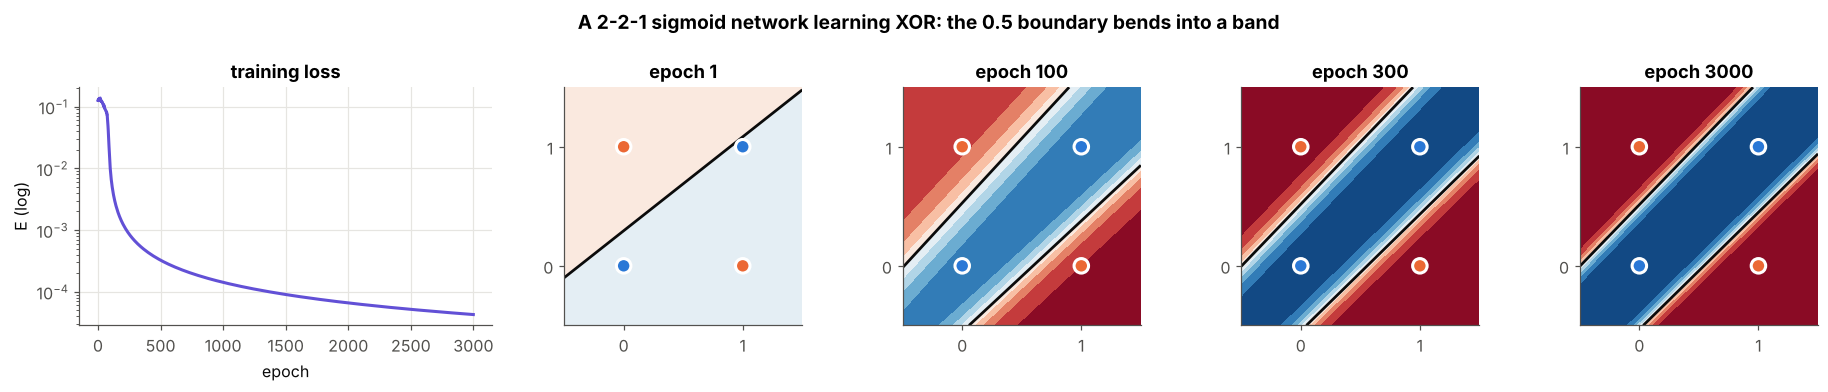

In [5]:
fig, axs = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1, 1]))
axs[0].semilogy(h_xor["loss"], color=C["violet"])
axs[0].set_title("training loss"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("E (log)")
for ax, (ep, S) in zip(axs[1:], xor_net.snapshots.items()):
    ax.contourf(gx, gy, S, levels=np.linspace(0, 1, 11), cmap="RdBu_r", vmin=0, vmax=1)
    ax.contour(gx, gy, S, levels=[0.5], colors=C["ink"], linewidths=1.8)
    ax.scatter(X_xor[0], X_xor[1], c=T_xor.ravel().astype(int), cmap=ListedColormap([C["blue"], C["orange"]]),
               s=90, edgecolor="white", linewidth=2, zorder=3)
    ax.set_title(f"epoch {ep}"); ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
fig.suptitle("A 2-2-1 sigmoid network learning XOR: the 0.5 boundary bends into a band", fontweight="bold")
plt.tight_layout(); plt.show()

The network found, *by itself*, a solution like the one we hand-built in module 01: two hidden "lines" whose combination makes a band.

> ⚠️ **Local minima.** With only 2 hidden units, some random starts get stuck (one hidden unit "dies" in a flat region and the output stays at 0.5 for two of the points). Try other `seed` values. Wider hidden layers make this far less likely – one practical reason networks are often bigger than strictly necessary.

---
## 5 · A harder problem: the 3-armed spiral 🌀

200 points per class wound around each other (480 for training, 120 held out for testing). No straight line (or two) can separate them.

train: 480 points, test: 120 points, one-hot targets (3, 480)


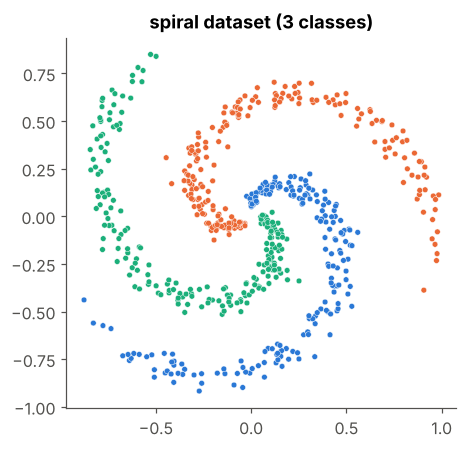

In [6]:
def make_spiral(n=200, k=3, noise=0.2, seed=0):
    """k interleaved spiral arms, n points each. Returns X (2 × nk) and labels y (nk,)."""
    r = np.random.default_rng(seed)
    X = np.zeros((2, n * k)); y = np.zeros(n * k, dtype=int)
    for j in range(k):
        ix = slice(n * j, n * (j + 1))
        rad = np.linspace(0.05, 1.0, n)                                     # radius grows along the arm
        th = np.linspace(j * 4, (j + 1) * 4, n) + r.normal(0, noise, n)    # angle, with noise
        X[:, ix] = np.vstack([rad * np.sin(th), rad * np.cos(th)])
        y[ix] = j
    return X, y

X, y = make_spiral()
perm = np.random.default_rng(0).permutation(X.shape[1])
X, y = X[:, perm], y[perm]
n_tr = int(0.8 * X.shape[1])
Xtr, ytr, Xte, yte = X[:, :n_tr], y[:n_tr], X[:, n_tr:], y[n_tr:]
Ttr, Tte = np.eye(3)[:, ytr], np.eye(3)[:, yte]                            # one-hot targets as columns
print(f"train: {Xtr.shape[1]} points, test: {Xte.shape[1]} points, one-hot targets {Ttr.shape}")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(X[0], X[1], c=y, cmap=SPIRAL_CMAP, s=14, edgecolor="white", linewidth=0.3)
ax.set_title("spiral dataset (3 classes)"); ax.set_aspect("equal"); ax.grid(False)
plt.tight_layout(); plt.show()

### Train a 2 → 64 → 64 → 3 network (ReLU hidden, softmax output)

In [7]:
gs = np.linspace(-1.2, 1.2, 250); sx, sy = np.meshgrid(gs, gs); SG = np.vstack([sx.ravel(), sy.ravel()])
spiral_snap = lambda net: net.predict(SG).reshape(sx.shape)

net = MLP([2, 64, 64, 3], hidden="relu", output="softmax_ce", seed=0)
hist = net.fit(Xtr, Ttr, Xte, Tte, epochs=150, batch=32, lr=0.05, momentum=0.9,
               snapshot_epochs=(1, 5, 20, 150), snapshot_fn=spiral_snap)
print(f"final train acc = {hist['acc'][-1]:.3f} | test acc = {hist['test_acc'][-1]:.3f} | "
      f"train loss = {hist['loss'][-1]:.4f}")

final train acc = 1.000 | test acc = 1.000 | train loss = 0.0010


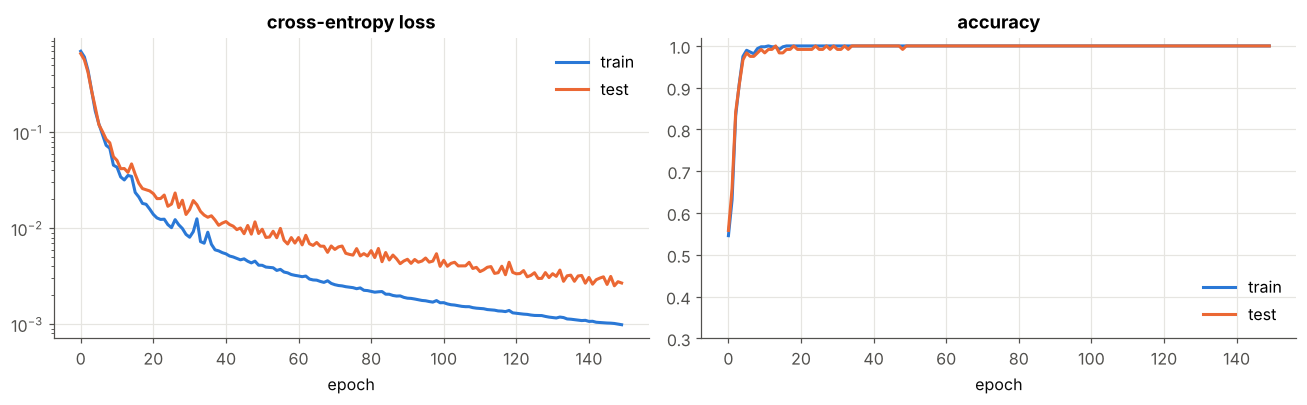

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(hist["loss"], color=C["blue"], label="train"); axs[0].plot(hist["test_loss"], color=C["orange"], label="test")
axs[0].set_yscale("log"); axs[0].set_title("cross-entropy loss"); axs[0].set_xlabel("epoch"); axs[0].legend()
axs[1].plot(hist["acc"], color=C["blue"], label="train"); axs[1].plot(hist["test_acc"], color=C["orange"], label="test")
axs[1].set_title("accuracy"); axs[1].set_xlabel("epoch"); axs[1].set_ylim(0.3, 1.02); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

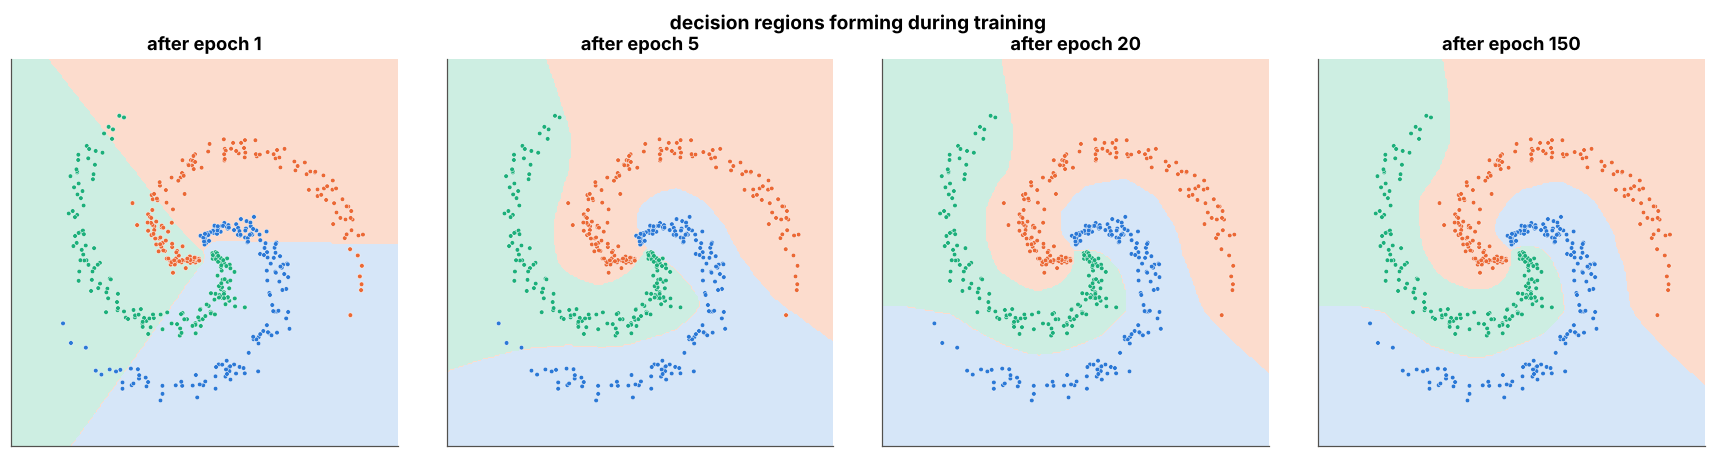

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (ep, S) in zip(axs, net.snapshots.items()):
    ax.contourf(sx, sy, S, levels=[-0.5, 0.5, 1.5, 2.5], cmap=REGION3_CMAP)
    ax.scatter(Xtr[0], Xtr[1], c=ytr, cmap=SPIRAL_CMAP, s=9, edgecolor="white", linewidth=0.3)
    ax.set_title(f"after epoch {ep}"); ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("decision regions forming during training", fontweight="bold")
plt.tight_layout(); plt.show()

Early on the regions are nearly straight wedges; as training proceeds the network bends them to follow each arm. Every bit of that shape came from the same five-step loop.

---
## 6 · The learning rate matters more than anything else 🎚️

Plain SGD (no momentum), 60 epochs, five learning rates:

η = 0.001  final train loss =   0.8385   test acc = 0.558
η = 0.01   final train loss =   0.5073   test acc = 0.808
η = 0.1    final train loss =   0.0306   test acc = 0.992
η = 1.0    final train loss =   0.0012   test acc = 1.000
η = 5.0    final train loss =   1.1139   test acc = 0.325


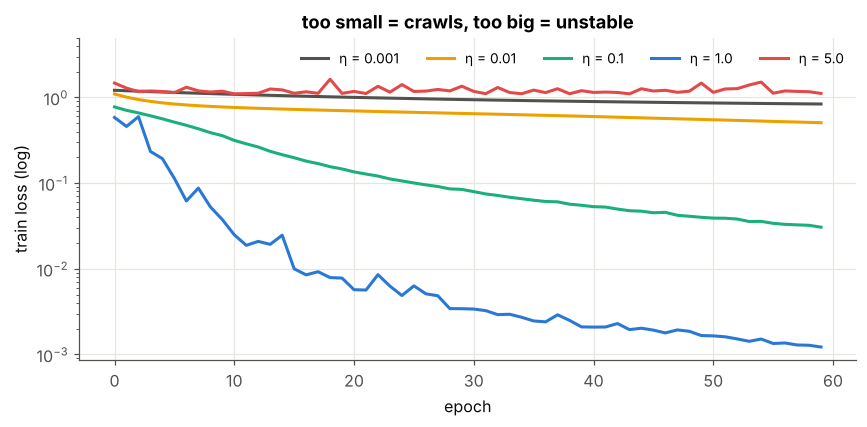

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for lr, col in zip((0.001, 0.01, 0.1, 1.0, 5.0), [C["muted"], C["yellow"], C["aqua"], C["blue"], C["red"]]):
    m = MLP([2, 64, 64, 3], seed=0)
    with np.errstate(all="ignore"):
        hh = m.fit(Xtr, Ttr, Xte, Tte, epochs=60, batch=32, lr=lr)
    ax.plot(hh["loss"], color=col, label=f"η = {lr}")
    print(f"η = {lr:<6} final train loss = {hh['loss'][-1]:8.4f}   test acc = {hh['test_acc'][-1]:.3f}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("train loss (log)"); ax.set_ylim(None, 5)
ax.set_title("too small = crawls, too big = unstable"); ax.legend(ncol=5, fontsize=9)
plt.tight_layout(); plt.show()

---
## 7 · Momentum and batch size ⚙️

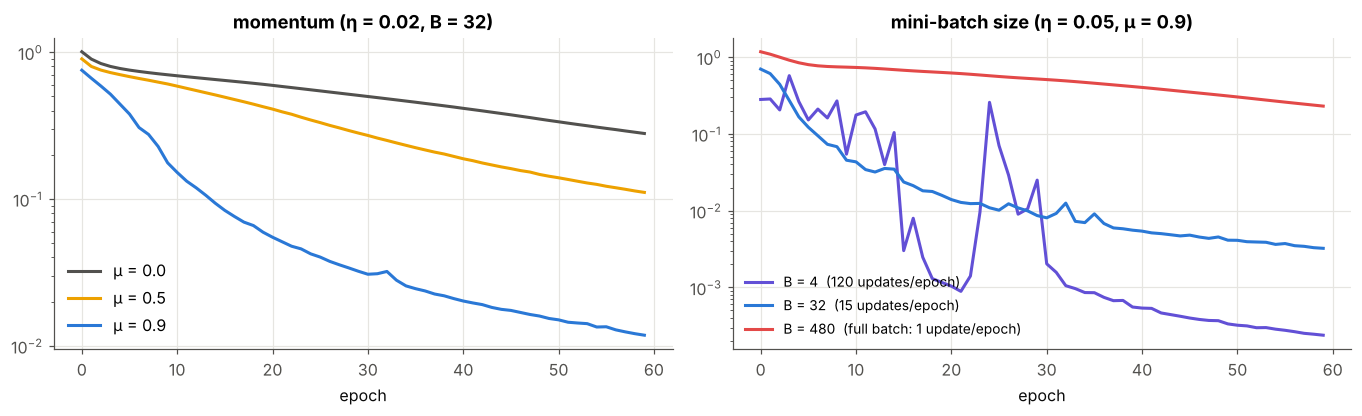

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
for mu, col in [(0.0, C["muted"]), (0.5, C["yellow"]), (0.9, C["blue"])]:
    hh = MLP([2, 64, 64, 3], seed=0).fit(Xtr, Ttr, epochs=60, batch=32, lr=0.02, momentum=mu)
    axs[0].plot(hh["loss"], color=col, label=f"μ = {mu}")
axs[0].set_yscale("log"); axs[0].set_title("momentum (η = 0.02, B = 32)"); axs[0].set_xlabel("epoch"); axs[0].legend()

for B, col in [(4, C["violet"]), (32, C["blue"]), (Xtr.shape[1], C["red"])]:
    hh = MLP([2, 64, 64, 3], seed=0).fit(Xtr, Ttr, epochs=60, batch=B, lr=0.05, momentum=0.9)
    lbl = f"B = {B}" + ("  (full batch: 1 update/epoch)" if B == Xtr.shape[1] else f"  ({int(np.ceil(Xtr.shape[1] / B))} updates/epoch)")
    axs[1].plot(hh["loss"], color=col, label=lbl)
axs[1].set_yscale("log"); axs[1].set_title("mini-batch size (η = 0.05, μ = 0.9)"); axs[1].set_xlabel("epoch"); axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

* **Momentum** reaches a given loss in far fewer epochs at the same $\eta$.
* **Small batches** make many cheap, noisy updates per epoch and progress fastest *per epoch* – but noisily: see the spikes for $B=4$, where single unlucky mini-batches kick the weights around; **full batch** makes one exact update per epoch and is slowest here. On a GPU, larger batches are cheaper *per example*, so in practice a middle size (32–512) is a common compromise.

---
## 8 · Summary 📌

| Ingredient | What it does |
|---|---|
| forward pass | $o^{[l]}=g(W^{[l]}o^{[l-1]}+b^{[l]})$, store everything |
| backward pass | $\delta^{[L]}$ from the loss, $\delta^{[l]}=g'\odot(W^{[l+1]})^\top\delta^{[l+1]}$ |
| update | $\Delta W^{[l]}=\eta\,\delta^{[l]}(o^{[l-1]})^\top$, with momentum $v\leftarrow\mu v-\eta g$ |
| mini-batches | many cheap noisy updates per epoch |
| results | XOR solved by a 2-2-1 sigmoid net; spiral: ~100% train / test accuracy with 2-64-64-3 |

### ✍️ Try it yourself
1. Train XOR with `seed` values 0–9. How many get stuck? Repeat with a `[2, 4, 1]` network.
2. Switch the spiral network to `hidden="sigmoid"`. How do speed and final accuracy change? (Remember notebook 04's vanishing-gradient plot.)
3. Add L2 weight decay to `step` (`g + λθ`) and watch the test loss.
4. Use `sklearn.datasets.load_digits` (8×8 digits) with `sizes=[64, 64, 10]`. What test accuracy do you get?

**Next →** `06 - Memory Footprint and Multi-GPU Training`: what happens when the network no longer fits on one GPU?